# SSFB Evaluation Analysis

Semantic State Feedback evaluation of an LLM against the APOLLO-SV ontology. This notebook runs an experiment end-to-end: loads the ontology, runs N trajectory runs against a local Ollama model, scores all responses, and visualizes the results.

## Configuration

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

from apollo_eval.ontology_loader import OntologyLoader
from apollo_eval.vocab import OntologyVocabularyBuilder
from apollo_eval.question import Question
from apollo_eval.question_loader import build_question_bank
from apollo_eval.model_client import OllamaClient
from apollo_eval.policy import PolicyEngine
from apollo_eval.evaluation import EvaluationLayer

# --- Experiment parameters (edit these) ---
N_RUNS = 5
BASE_SEED = 42
OUTPUT_DIR = "trajectories"
SCENARIO_IRI = "http://example.org/scenario/measles_epidemic/"
SIMILARITY_THRESHOLD = 1.0   # 1.0 = exact only, 0.65 = fuzzy
MODEL = None                  # None = use default (llama3.2:1b)

# --- Set this to load a previous experiment instead of running a new one ---
# Example: LOAD_EXPERIMENT = "trajectories/notebook_run"
LOAD_EXPERIMENT = None        # None = run new experiment

# --- Plot style ---
sns.set_theme(style="whitegrid", font_scale=1.1)
TYPE_COLORS = {"CM": "#4C72B0", "PR": "#DD8452", "DJ": "#55A868"}
TYPE_LABELS = {"CM": "Class Membership", "PR": "Property Restriction", "DJ": "Disjointness"}

## Load Ontology and Build Questions

In [2]:
loader = OntologyLoader()
graph = loader.load_graph()
graph = loader.apply_reasoning(graph)
ontology = OntologyVocabularyBuilder(graph).build(
    similarity_threshold=SIMILARITY_THRESHOLD,
)
Question.ontology = ontology
questions = build_question_bank(ontology)
print(f"{len(questions)} questions ready.")

25 questions ready.


## Run Experiment

Set `LOAD_EXPERIMENT` in the configuration cell to a path (e.g. `"trajectories/notebook_run"`) to skip this step and load previous results instead.

In [ ]:
from datetime import datetime

if LOAD_EXPERIMENT:
    experiment_dir = LOAD_EXPERIMENT
    n_files = len([f for f in os.listdir(experiment_dir) if f.endswith(".json")])
    print(f"Loading existing experiment from: {experiment_dir} ({n_files} runs)")
else:
    experiment_id = datetime.now().strftime("%Y%m%d_%H%M%S")
    experiment_dir = os.path.join(OUTPUT_DIR, experiment_id)
    os.makedirs(experiment_dir, exist_ok=True)
    print(f"Experiment directory: {experiment_dir}")

    for i in range(N_RUNS):
        client = OllamaClient(model=MODEL)
        engine = PolicyEngine(
            questions=questions,
            client=client,
            seed=BASE_SEED + i,
            scenario_iri=SCENARIO_IRI,
        )
        engine.run()
        engine.save(experiment_dir)
        print(f"Run {i + 1}/{N_RUNS}: {engine.run_id}")

    print("Done.")

## Process Results

Re-score all trajectories and build the evaluation DataFrame.

In [ ]:
evaluator = EvaluationLayer(experiment_dir, questions)
df = evaluator.build_dataframe()

q_summary = evaluator.summary_by_question(df)
qt_summary = evaluator.summary_by_question_type(df)
pos_summary = evaluator.summary_by_position(df)
run_summary = evaluator.summary_by_run(df)
exp = evaluator.experiment_summary(df)

print(f"Experiment: {experiment_dir}")
print(f"Total turns: {exp['total_turns']}")
print(f"Runs: {exp['n_runs']}  |  Questions: {exp['n_questions']}")
print(f"Parse rate: {exp['parse_rate']:.1%}")
print(f"Overall consistency: {exp['consistency_rate']:.1%}")
for qt in ("CM", "PR", "DJ"):
    cr = exp[f"{qt}_consistency_rate"]
    pfr = exp[f"{qt}_parse_failure_rate"]
    cr_str = f"{cr:.1%}" if cr == cr else "N/A"
    print(f"  {qt}: consistency={cr_str}  parse_failure={pfr:.1%}")

## Consistency Rate by Question

Each bar is one question, colored by type (CM = Class Membership, PR = Property Restriction, DJ = Disjointness).

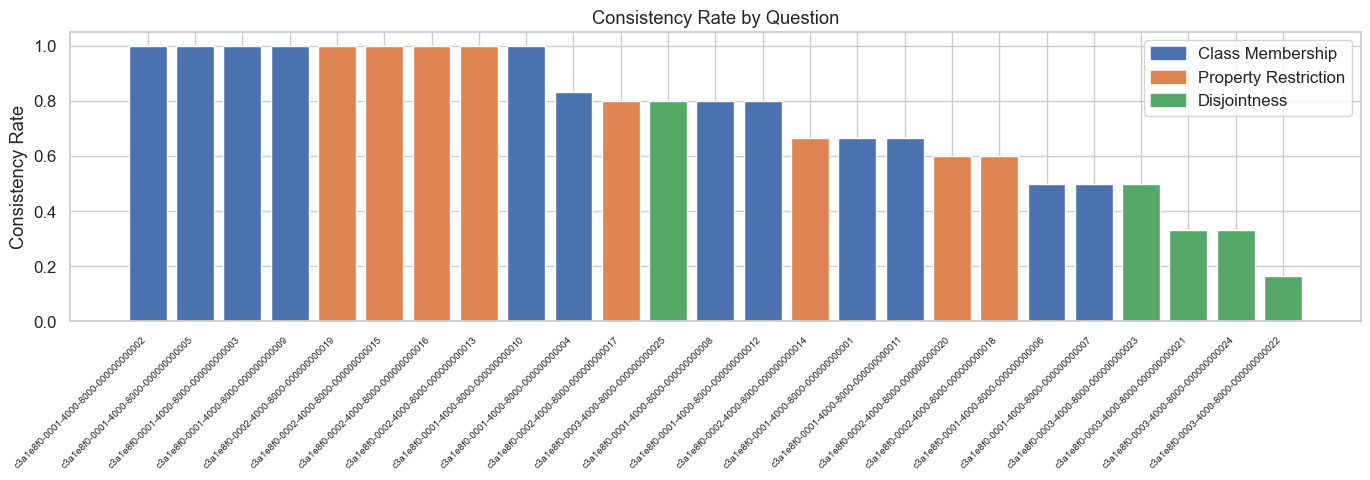

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
q_sorted = q_summary.sort_values("consistency_rate", ascending=False)
colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
bars = ax.bar(range(len(q_sorted)), q_sorted["consistency_rate"], color=colors)
ax.set_xticks(range(len(q_sorted)))
ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate by Question")
ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
plt.tight_layout()
plt.show()

## Consistency Rate by Question Type

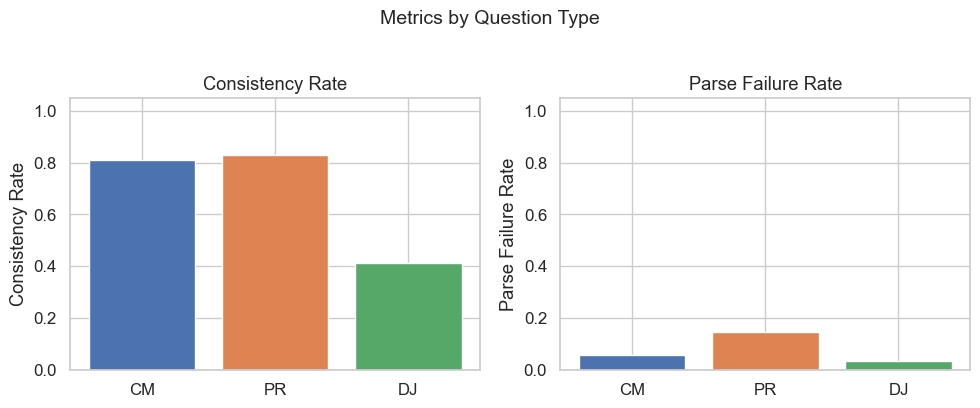

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Consistency rate
ax = axes[0]
qt_order = ["CM", "PR", "DJ"]
qt_plot = qt_summary.loc[qt_order]
ax.bar(qt_order, qt_plot["consistency_rate"], color=[TYPE_COLORS[t] for t in qt_order])
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate")

# Parse failure rate
ax = axes[1]
ax.bar(qt_order, qt_plot["parse_failure_rate"], color=[TYPE_COLORS[t] for t in qt_order])
ax.set_ylabel("Parse Failure Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Parse Failure Rate")

plt.suptitle("Metrics by Question Type", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Position Effect

Does consistency degrade as the conversation progresses? Each point is the mean consistency rate across all runs at that turn position.

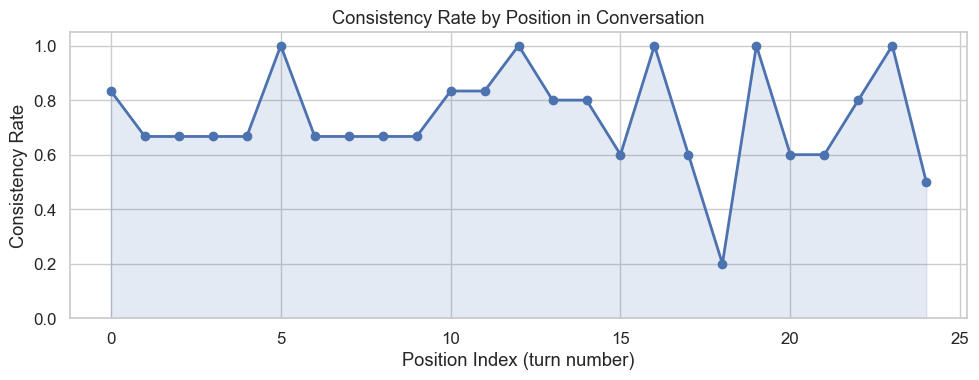

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pos_summary.index, pos_summary["consistency_rate"], marker="o", linewidth=2, color="#4C72B0")
ax.fill_between(pos_summary.index, pos_summary["consistency_rate"], alpha=0.15, color="#4C72B0")
ax.set_xlabel("Position Index (turn number)")
ax.set_ylabel("Consistency Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Consistency Rate by Position in Conversation")
plt.tight_layout()
plt.show()

## Parse Failure Rate by Question

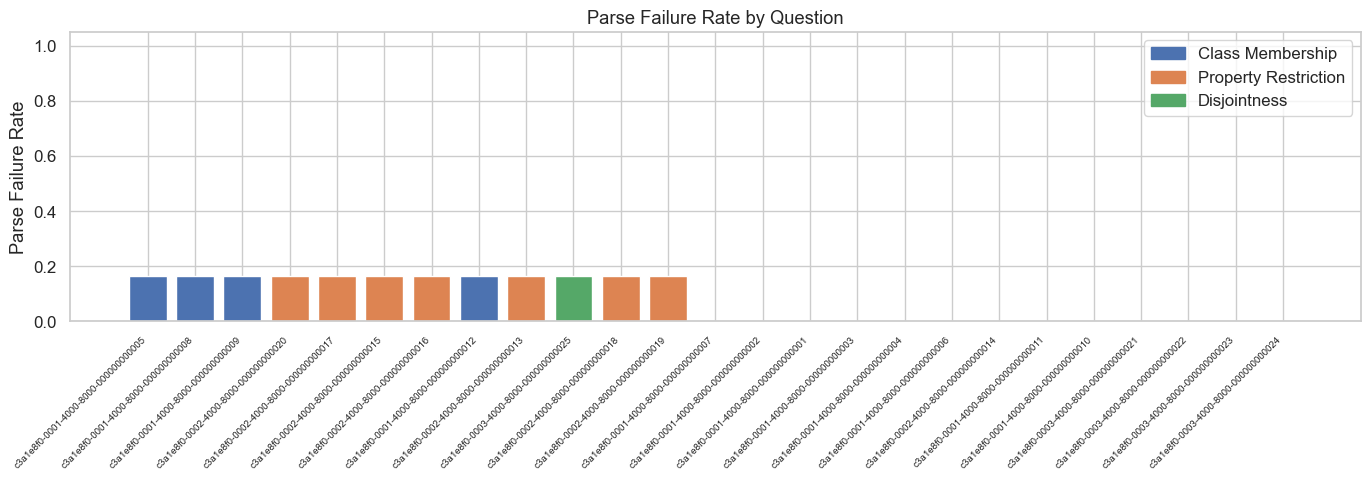

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
q_sorted = q_summary.sort_values("parse_failure_rate", ascending=False)
colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
ax.bar(range(len(q_sorted)), q_sorted["parse_failure_rate"], color=colors)
ax.set_xticks(range(len(q_sorted)))
ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Parse Failure Rate")
ax.set_ylim(0, 1.05)
ax.set_title("Parse Failure Rate by Question")
ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
plt.tight_layout()
plt.show()

## Similarity Fallback Rate

Only meaningful when `SIMILARITY_THRESHOLD < 1.0`. Shows how often the fuzzy matching fallback was used.

In [9]:
if SIMILARITY_THRESHOLD < 1.0:
    fig, ax = plt.subplots(figsize=(14, 5))
    q_sorted = q_summary.sort_values("fuzz_rate", ascending=False)
    colors = [TYPE_COLORS[t] for t in q_sorted["question_type"]]
    ax.bar(range(len(q_sorted)), q_sorted["fuzz_rate"].fillna(0), color=colors)
    ax.set_xticks(range(len(q_sorted)))
    ax.set_xticklabels(q_sorted.index, rotation=45, ha="right", fontsize=7)
    ax.set_ylabel("Fuzz Rate (similarity fallback)")
    ax.set_ylim(0, 1.05)
    ax.set_title("Similarity Fallback Rate by Question")
    ax.legend(handles=[Patch(color=c, label=TYPE_LABELS[k]) for k, c in TYPE_COLORS.items()])
    plt.tight_layout()
    plt.show()
else:
    print("Similarity matching disabled (threshold=1.0). Skipping fuzz rate chart.")

Similarity matching disabled (threshold=1.0). Skipping fuzz rate chart.


## Per-Run Consistency

Variance across independent seeds. The red dashed line is the overall mean.

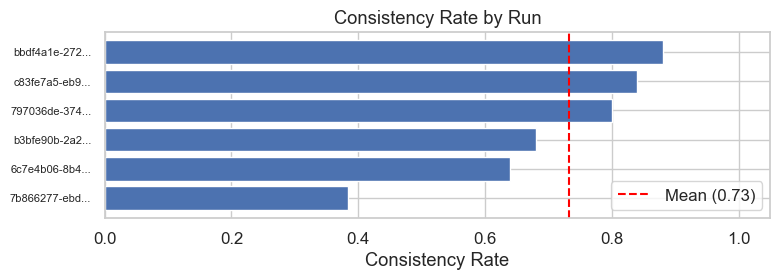

In [12]:
fig, ax = plt.subplots(figsize=(8, max(3, len(run_summary) * 0.4)))
run_sorted = run_summary.sort_values("consistency_rate")
ax.barh(range(len(run_sorted)), run_sorted["consistency_rate"], color="#4C72B0")
ax.set_yticks(range(len(run_sorted)))
ax.set_yticklabels([r[:12] + "..." for r in run_sorted.index], fontsize=8)
ax.set_xlabel("Consistency Rate")
ax.set_xlim(0, 1.05)
ax.set_title("Consistency Rate by Run")
ax.axvline(exp["consistency_rate"], color="red", linestyle="--", linewidth=1.5, label=f"Mean ({exp['consistency_rate']:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

## Experiment Summary

In [11]:
def fmt_pct(v):
    return f"{v:.1%}" if v == v else "N/A"

summary_rows = [
    ("Total Turns", str(exp["total_turns"])),
    ("Runs", str(exp["n_runs"])),
    ("Questions", str(exp["n_questions"])),
    ("Parse Rate", fmt_pct(exp["parse_rate"])),
    ("Overall Consistency", fmt_pct(exp["consistency_rate"])),
    ("", ""),
    ("CM Consistency", fmt_pct(exp["CM_consistency_rate"])),
    ("CM Parse Failure", fmt_pct(exp["CM_parse_failure_rate"])),
    ("PR Consistency", fmt_pct(exp["PR_consistency_rate"])),
    ("PR Parse Failure", fmt_pct(exp["PR_parse_failure_rate"])),
    ("DJ Consistency", fmt_pct(exp["DJ_consistency_rate"])),
    ("DJ Parse Failure", fmt_pct(exp["DJ_parse_failure_rate"])),
]

summary_df = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
summary_df = summary_df[summary_df["Metric"] != ""]
summary_df.style.hide(axis="index")

Metric,Value
Total Turns,150
Runs,6
Questions,25
Parse Rate,92.0%
Overall Consistency,73.2%
CM Consistency,80.9%
CM Parse Failure,5.6%
PR Consistency,82.9%
PR Parse Failure,14.6%
DJ Consistency,41.4%
